In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
sns.set_theme(style="whitegrid")
conn = sqlite3.connect('tmdb_movies.db')
movies = pd.read_sql_query("SELECT * FROM movies", conn)
genres = pd.read_sql_query("SELECT * FROM genres", conn)
movie_genres = pd.read_sql_query("SELECT * FROM movie_genres", conn)
conn.close()



In [3]:
movies['release_year'] = pd.to_datetime(movies['release_date'], errors='coerce').dt.year
movies['decade'] = (movies['release_year'] // 10) * 10
primary_g = movie_genres.drop_duplicates('movie_id').merge(genres, on='genre_id')
df = movies.merge(primary_g[['movie_id', 'genre_name']], on='movie_id', how='left')
df['genre_name'] = df['genre_name'].fillna('Unknown')
valid_fin = df[(df['budget'] > 0) & (df['revenue'] > 0)]



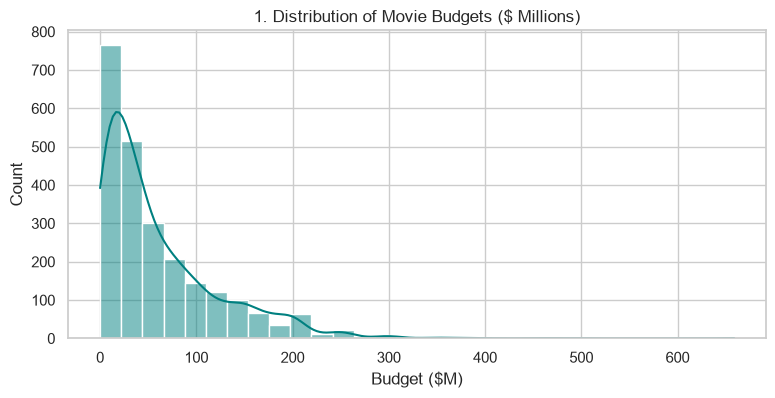

In [4]:
# 1. UNIVARIATE: Distribution of Movie Budgets
plt.figure(figsize=(9, 4))
sns.histplot(valid_fin['budget'] / 1e6, bins=30, kde=True, color='teal')
plt.title('1. Distribution of Movie Budgets ($ Millions)')
plt.xlabel('Budget ($M)')
plt.show()
# Insight: Movie budgets are heavily right-skewed, with the majority of films produced under $40M while a small tier of blockbusters exceeds $150M.


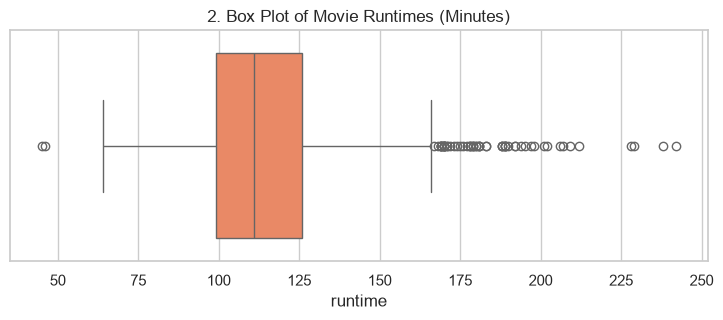

In [5]:

# 2. UNIVARIATE: Distribution of Runtimes
plt.figure(figsize=(9, 3))
sns.boxplot(x=df[df['runtime'] > 0]['runtime'], color='coral')
plt.title('2. Box Plot of Movie Runtimes (Minutes)')
plt.show()
# Insight: Most commercial releases cluster tightly between 95 and 120 minutes, with notable upper-end outliers exceeding 180 minutes.


C:\Users\arpit\AppData\Local\Temp\ipykernel_23392\409510950.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=mg_full, y='genre_name', order=mg_full['genre_name'].value_counts().index, palette='viridis')


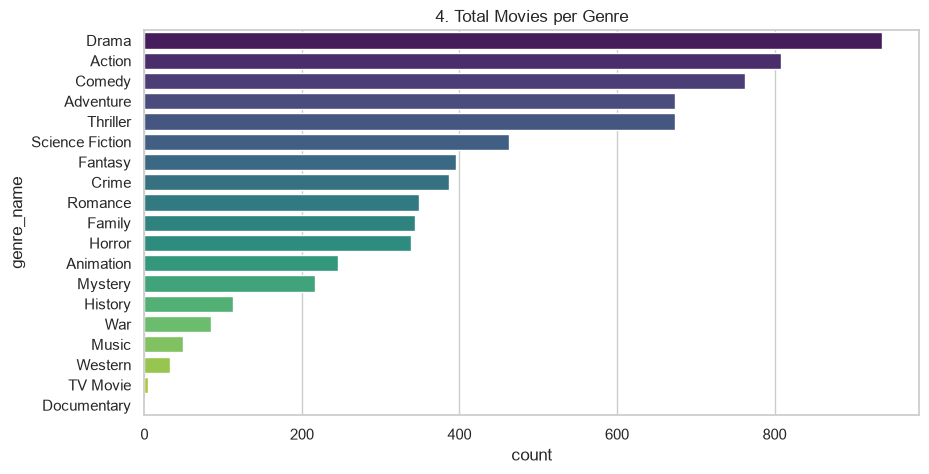

In [6]:
# 4. UNIVARIATE: Count of Movies per Genre
mg_full = movie_genres.merge(genres, on='genre_id')
plt.figure(figsize=(10, 5))
sns.countplot(data=mg_full, y='genre_name', order=mg_full['genre_name'].value_counts().index, palette='viridis')
plt.title('4. Total Movies per Genre')
plt.show()
# Insight: Drama, Comedy, and Thriller dominate catalog volume, whereas niche genres like Western and Documentary account for a small fraction of output.


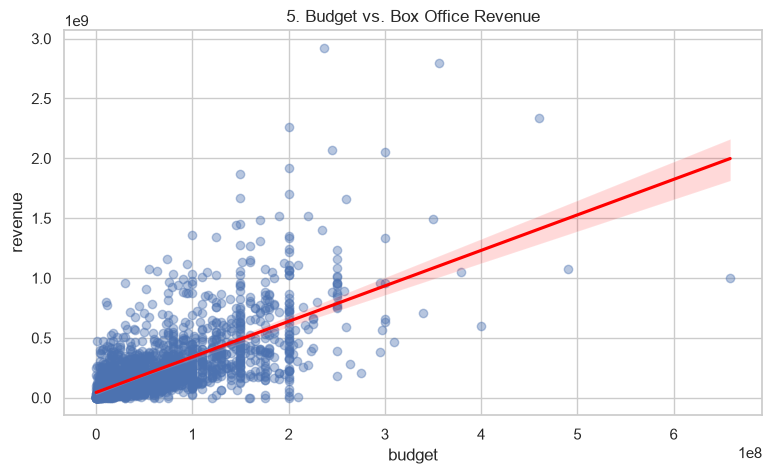

In [7]:

# 5. BIVARIATE: Budget vs Revenue with Trendline
plt.figure(figsize=(9, 5))
sns.regplot(data=valid_fin, x='budget', y='revenue', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title('5. Budget vs. Box Office Revenue')
plt.show()
# Insight: There is a strong positive linear relationship between production budget and box office return, though variance widens sharply at higher budget tiers.


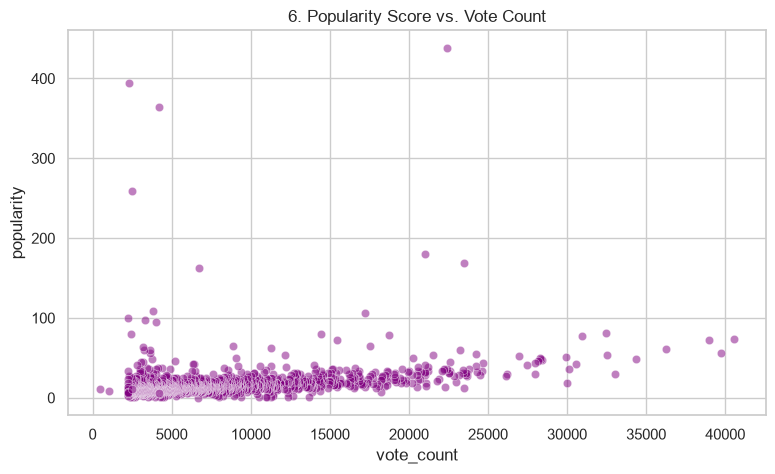

In [8]:

# 6. BIVARIATE: Popularity vs Vote Count
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='vote_count', y='popularity', alpha=0.5, color='purple')
plt.title('6. Popularity Score vs. Vote Count')
plt.show()
# Insight: While high vote counts generally correspond to steady popularity, newly released or trending films often exhibit extreme popularity spikes despite low vote counts.


C:\Users\arpit\AppData\Local\Temp\ipykernel_23392\3102380670.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_ratings.values, y=genre_ratings.index, palette='magma') #seaborn


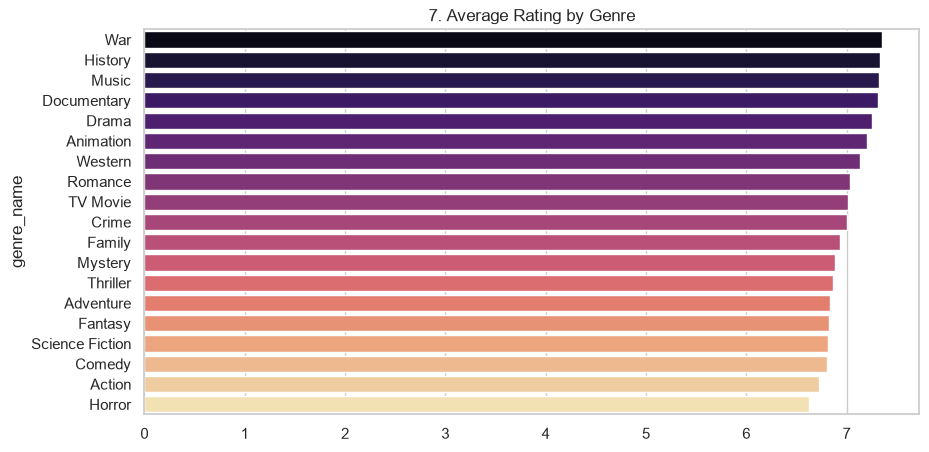

In [9]:

# 7. BIVARIATE: Average Rating by Genre
genre_ratings = mg_full.merge(movies, on='movie_id').groupby('genre_name')['vote_average'].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=genre_ratings.values, y=genre_ratings.index, palette='magma') #seaborn
plt.title('7. Average Rating by Genre')
plt.show()
# Insight: History, War, and Drama consistently earn higher 
# critical/audience ratings than Horror or Action titles.


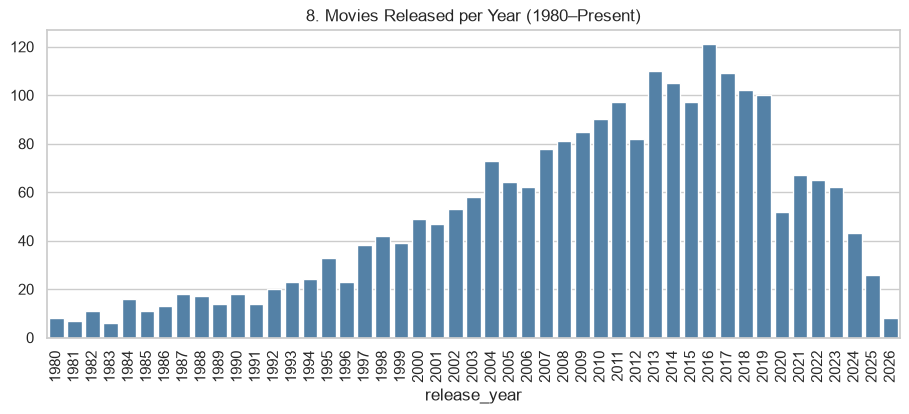

In [10]:
# 8. BIVARIATE: Number of Movies Released per Year
yearly = df[df['release_year'] >= 1980]['release_year'].value_counts().sort_index()
plt.figure(figsize=(11, 4))
sns.barplot(x=yearly.index.astype(int), y=yearly.values, color='steelblue')
plt.xticks(rotation=90)
plt.title('8. Movies Released per Year (1980–Present)')
plt.show()
# Insight: Annual production volume grew steadily through the 2000s and 2010s, 
# reflecting expanded global distribution and dataset coverage.


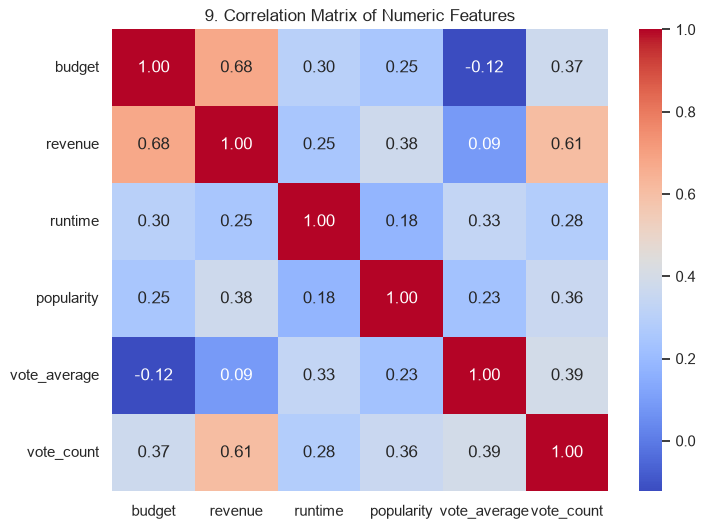

In [11]:

# 9. MULTIVARIATE: Correlation Heatmap
plt.figure(figsize=(8, 6))
cols = ['budget', 'revenue', 'runtime', 'popularity', 'vote_average', 'vote_count']
sns.heatmap(valid_fin[cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('9. Correlation Matrix of Numeric Features')
plt.show()
# Insight: Revenue correlates strongest with budget (0.7+) and vote_count (0.7+),
#  while runtime and vote_average show weak correlation with financial scale.


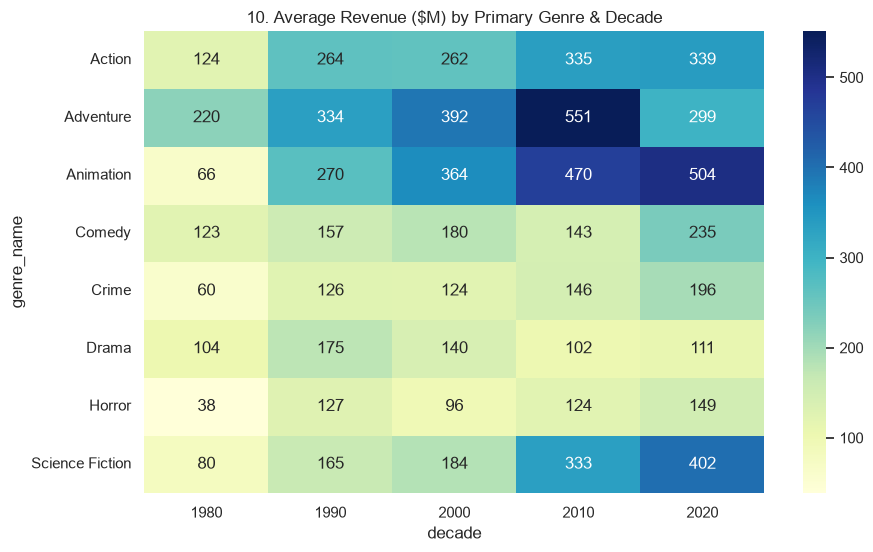

In [12]:

# 10. MULTIVARIATE: Average Revenue by Genre and Decade
top_genres = valid_fin['genre_name'].value_counts().head(8).index
pivot_rev = valid_fin[valid_fin['genre_name'].isin(top_genres) & (valid_fin['decade'] >= 1980)].pivot_table(
    index='genre_name', columns='decade', values='revenue', aggfunc='mean'
) / 1e6
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_rev, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('10. Average Revenue ($M) by Primary Genre & Decade')
plt.show()
# Insight: Adventure and Action franchises experienced massive 
# revenue expansion from the 1990s to the 2010s compared to mid-budget Dramas.



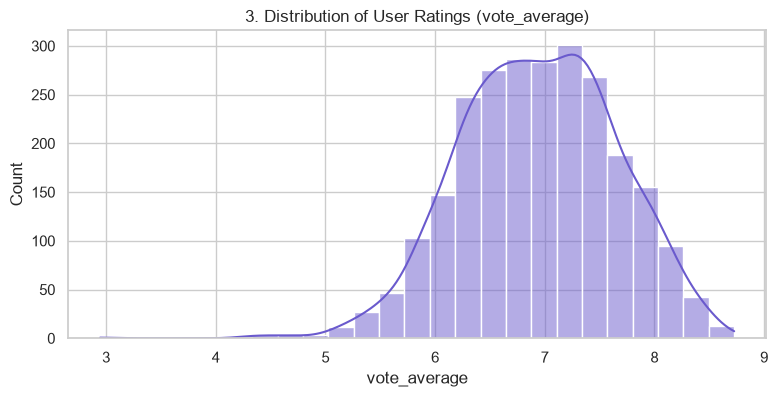

In [13]:
# 3. UNIVARIATE: Distribution of Vote Average
plt.figure(figsize=(9, 4))
sns.histplot(df[df['vote_count'] > 10]['vote_average'], bins=25, kde=True, color='slateblue')
plt.title('3. Distribution of User Ratings (vote_average)')
plt.show()
# Insight: Audience ratings follow a roughly normal distribution centered around 6.3/10, 
# indicating very few films achieve scores above 8.0 or below 4.0.
